# Audio

In [1]:
#%pip install ipython-autotime

In [2]:
# autotime prints how long every cell took -- useful when you start timing
# model calls against API calls.
%load_ext autotime

time: 45 μs (started: 2026-11-06 00:37:49 +05:30)


In [3]:
import os, json, base64, subprocess, warnings
from pathlib import Path

import numpy as np
import librosa
import soundfile as sf
import torch
import cv2
import matplotlib.pyplot as plt
from IPython.display import Audio, display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": "#FCFAF4", "axes.grid": True,
    "grid.color": "#E6E0D4", "axes.titleweight": "bold", "font.size": 10,
})

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")

print("numpy", np.__version__, "| librosa", librosa.__version__,
      "| torch", torch.__version__, "| cv2", cv2.__version__)
print("device:", device)

numpy 2.3.5 | librosa 1.0.0 | torch 2.15.0 | cv2 5.0.0
device: mps
time: 5.62 s (started: 2026-11-06 00:37:49 +05:30)


In [4]:
import textwrap
from dotenv import load_dotenv
from openai import OpenAI

# Optional -- only needed if you are behind a VPN
#import truststore
#truststore.inject_into_ssl()


def pretty_print(*args):
    text = " ".join(str(arg) for arg in args)
    try:
        print(textwrap.fill(text, width=80))
    except Exception:
        print(text)


load_dotenv('/Users/pranjalimhatre/Scaler/AdvancedAI/openAIKey.env')

if not os.getenv("OPENAI_API_KEY"):
    raise ValueError("OPENAI_API_KEY not found! Check the path in load_dotenv above.")

client = OpenAI()
pretty_print("API key loaded, client ready.")

API key loaded, client ready.
time: 633 ms (started: 2026-11-06 00:37:54 +05:30)


In [5]:
# ---- everything the notebook is configured by, in one place ---------------

SR = 16_000                              # THE speech sample rate. Everything is 16k.

ASR_MODEL_ID = "openai/whisper-base.en"  # fast classroom default (73M params)
# ASR_MODEL_ID = "openai/whisper-large-v3-turbo"   # what you'd actually ship

VISION_MODEL = "gpt-5-nano"              # any vision model: gpt-4o, gpt-4.1, gpt-5-*
OPENAI_ASR   = "gpt-4o-transcribe"       # managed speech-to-text
OPENAI_TTS   = "gpt-4o-mini-tts"         # managed text-to-speech
SEGMENT_ASR  = "whisper-1"               # the only one that returns SEGMENT timestamps

VIDEO_PATH = "/Users/pranjalimhatre/Scaler/AdvancedAI/LLMs_OtherModalities/AI Modalities: Video/videos/What is your name.mov"

CACHE = Path("audio_cache")              # pre-fetched clips live here

print("ASR (local) :", ASR_MODEL_ID)
print("vision      :", VISION_MODEL)
print("video       :", Path(VIDEO_PATH).name, "|  exists:", os.path.exists(VIDEO_PATH))

ASR (local) : openai/whisper-base.en
vision      : gpt-5-nano
video       : What is your name.mov |  exists: True
time: 738 μs (started: 2026-11-06 00:37:55 +05:30)


### 20Hz to 20kHz is the human hearing range. 16kHz is a good compromise for speech, and is what Whisper uses.

In [6]:
# Frequency = how fast the wave wobbles = what you hear as PITCH.
# Same amplitude (0.3) every time, so the ONLY thing changing is speed.
sr_demo, duration = 44_100, 2.0
t = np.linspace(0, duration, int(sr_demo * duration), endpoint=False)

for hz, label in [(100, "deep"), (1000, "sharp"), (10_000, "very sharp"),
                  (15_000, "near the top of adult hearing"), (18_000, "near the top of young adult hearing"), (20_000, "top of human hearing"), (25_000, "beyond human hearing")]:
    print(f"{hz:>6} Hz  ({label})")
    display(Audio(0.3 * np.sin(2 * np.pi * hz * t), rate=sr_demo))

   100 Hz  (deep)


  1000 Hz  (sharp)


 10000 Hz  (very sharp)


 15000 Hz  (near the top of adult hearing)


 18000 Hz  (near the top of young adult hearing)


 20000 Hz  (top of human hearing)


 25000 Hz  (beyond human hearing)


time: 16.7 ms (started: 2026-11-06 00:37:55 +05:30)


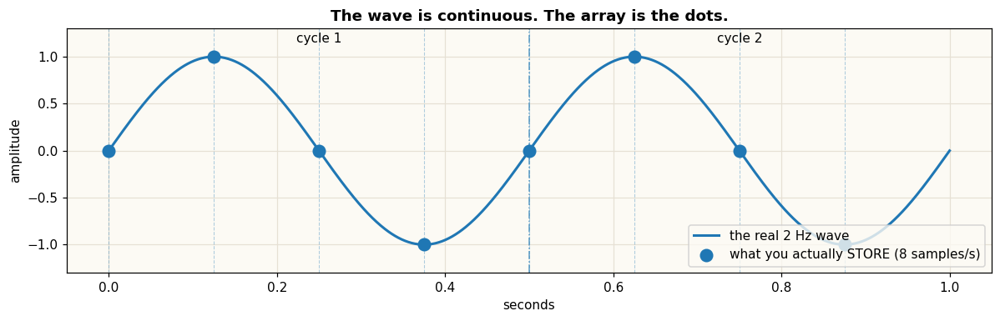

samples per cycle: 4.0
the array you'd store: [ 0.  1.  0. -1. -0.  1.  0. -1.]
time: 513 ms (started: 2026-11-06 00:37:55 +05:30)


In [7]:
sound_frequency = 2      # 2 cycles per second
sampling_rate   = 8      # 8 measurements per second

t_smooth  = np.linspace(0, 1.0, 1000)
y_smooth  = np.sin(2 * np.pi * sound_frequency * t_smooth)
t_samples = np.arange(0, 1.0, 1 / sampling_rate)
y_samples = np.sin(2 * np.pi * sound_frequency * t_samples)

plt.figure(figsize=(11, 3.6))
plt.plot(t_smooth, y_smooth, lw=2, label=f"the real {sound_frequency} Hz wave")
plt.scatter(t_samples, y_samples, s=90, zorder=3,
            label=f"what you actually STORE ({sampling_rate} samples/s)")
for tick in t_samples:
    plt.axvline(tick, ls="--", lw=0.7, alpha=0.35)
plt.axvline(0.5, ls="-.", lw=1, alpha=0.7)
plt.text(0.25, 1.15, "cycle 1", ha="center"); plt.text(0.75, 1.15, "cycle 2", ha="center")
plt.title("The wave is continuous. The array is the dots."); plt.xlabel("seconds")
plt.ylabel("amplitude"); plt.ylim(-1.3, 1.3); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

print("samples per cycle:", sampling_rate / sound_frequency)
print("the array you'd store:", np.round(y_samples, 2))

In [8]:
# A cached LibriSpeech clip. Decoded with soundfile (never torchcodec).
y16, sr0 = sf.read(CACHE / "librispeech_dummy.wav", dtype="float32")
ref_text = json.load(open(CACHE / "librispeech_dummy_meta.json"))["ref_text"]

print(f"samples  : {len(y16):,}   sr: {sr0} Hz   duration: {len(y16)/sr0:.2f}s")
print(f"dtype    : {y16.dtype}   range: [{y16.min():+.3f}, {y16.max():+.3f}]"
      "   <- floats in [-1, 1], which is what models want")
print(f"reference: {ref_text!r}")
display(Audio(y16, rate=SR))

samples  : 93,680   sr: 16000 Hz   duration: 5.86s
dtype    : float32   range: [-0.339, +0.388]   <- floats in [-1, 1], which is what models want
reference: 'MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL'


time: 6.13 ms (started: 2026-11-06 00:37:56 +05:30)


In [9]:
print(os.path.exists('audio_cache'))

True
time: 338 μs (started: 2026-11-06 00:37:56 +05:30)


In [10]:
import transformers
from transformers import WhisperProcessor, WhisperForConditionalGeneration

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()   # HuggingFace's generation notices are noisy in class

processor = WhisperProcessor.from_pretrained(ASR_MODEL_ID)
model = WhisperForConditionalGeneration.from_pretrained(ASR_MODEL_ID).to(device).eval()

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"loaded {ASR_MODEL_ID}  (~{n_params:.0f}M params) on {device}")

W1106 00:38:00.045000 83155 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

loaded openai/whisper-base.en  (~73M params) on mps
time: 7.14 s (started: 2026-11-06 00:37:56 +05:30)


In [11]:
# NOTE sampling_rate=16_000. This MUST match the audio's true rate --
# it is the Part 3 footgun, made concrete right here.
feats = processor(y16, sampling_rate=SR, return_tensors="pt").input_features.to(device)
print("input_features:", tuple(feats.shape), "= (batch, 80 mel bands, frames)")

with torch.no_grad():
    ids = model.generate(feats, max_new_tokens=128)

hyp = processor.batch_decode(ids, skip_special_tokens=True)[0].strip()
print("\nhypothesis:", hyp)
print("reference :", ref_text)
display(Audio(y16, rate=SR))

input_features: (1, 80, 3000) = (batch, 80 mel bands, frames)

hypothesis: Mr. Quilter is the apostle of the middle classes, and we are glad to welcome his gospel.
reference : MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL


time: 327 ms (started: 2026-11-06 00:38:03 +05:30)


In [12]:
from jiwer import wer # word error rate

_ref = "the quick brown fox jumps over the lazy dog"
_hyp = "the quick brown fox jump over lazy dog"       # 1 substitution + 1 deletion

print("reference :", _ref)
print("hypothesis:", _hyp)
print(f"WER       : {wer(_ref, _hyp):.3f}   (2 errors / 9 reference words)")

# Use word error rate to find out what the difference is between the references and the hypothesis
# for the model that you're using. 
# The hypothesis is the result that we get from the speech recognition model that we are using, 
# and by calculating the word error rate, we would be able to find out how good the model is. 

reference : the quick brown fox jumps over the lazy dog
hypothesis: the quick brown fox jump over lazy dog
WER       : 0.222   (2 errors / 9 reference words)
time: 70.4 ms (started: 2026-11-06 00:38:03 +05:30)


In [13]:
# --- speech -> text --------------------------------------------------------
with open("test_audio.m4a", "rb") as audio_file:
    transcription = client.audio.transcriptions.create(
        model=OPENAI_ASR,
        file=audio_file,
    )

print("transcribed:", transcription.text)

# Audio is billed as TOKENS too -- and they are input tokens, like any prompt.
u = transcription.usage
print("\ninput tokens :", u.input_tokens, " of which audio:",
      u.input_token_details.audio_tokens)
print("output tokens:", u.output_tokens, "| total:", u.total_tokens)

transcribed: Hello. It's Wednesday, November 4th, 2026, and 4:46 in the morning, and we are making this video, recording this video, to test LLM Other Modalities lecture, to test an audio for Other Modalities lecture.

input tokens : 285  of which audio: 285
output tokens: 55 | total: 340
time: 3.23 s (started: 2026-11-06 00:38:04 +05:30)


In [14]:
vad_model, vad_utils = torch.hub.load("snakers4/silero-vad", "silero_vad",
                                      trust_repo=True)
get_speech_timestamps = vad_utils[0]

# Silero wants 16 kHz mono float32 as a torch tensor.
speech = get_speech_timestamps(torch.from_numpy(np.ascontiguousarray(y16)),
                               vad_model, sampling_rate=SR, return_seconds=True)

print(f"clip is {len(y16)/SR:.2f}s long; VAD found {len(speech)} speech segment(s):")
for s in speech:
    print(f"  speech {s['start']:.2f}s -> {s['end']:.2f}s")

# This silero VAD model tells us at what interval in a  audio the exact audio is present.
# Let's say there is a chunk of audio from the 5th second to the 10th second, 
# but from 0 to 5 seconds, we don't have anything. 
# The Silero VAD model helps us to find these chunks where the actual audio is present. 
# That way, we can reduce the size of the audio, and we can send those chunks for 
# speech-to-text conversion. 

clip is 5.86s long; VAD found 1 speech segment(s):
  speech 0.50s -> 5.50s
time: 769 ms (started: 2026-11-06 00:38:07 +05:30)


Using cache found in /Users/pranjalimhatre/.cache/torch/hub/snakers4_silero-vad_master


In [15]:
# --- text -> speech --------------------------------------------------------
speech_file_path = Path("tutor_voice.mp3")

with client.audio.speech.with_streaming_response.create(
    model=OPENAI_TTS,
    voice="nova",                      # alloy, echo, fable, onyx, nova, shimmer
    input="Hey there! Today we will explore AI that can see, listen, and speak. " \
    "And also eat your wallet."
) as response:
    response.stream_to_file(speech_file_path)

print("saved:", speech_file_path, f"({speech_file_path.stat().st_size/1024:.0f} KB)")
display(Audio(str(speech_file_path)))

saved: tutor_voice.mp3 (111 KB)


time: 2.36 s (started: 2026-11-06 00:38:08 +05:30)


# Video understanding 

In [16]:
# --- 1) an image by URL, cheap setting -------------------------------------
IMAGE_URL = "https://www.animesenpai.net/wp-content/uploads/2023/12/sef-min.png.webp"
# Jujutsu Kaisen Hanami. 

vision_response = client.chat.completions.create(
    model=VISION_MODEL, # gpt-5-nano
    messages=[
        {"role": "system",
         "content": "You are an art critic who gives gentle feedback on illustrations."},
        {"role": "user", "content": [
            {"type": "text", "text": "Analyze this illustration in 3 sentences."},
            {"type": "image_url", "image_url": {
                "url": IMAGE_URL,
                "detail": "low",          # "low" | "high" | "auto"
            }},
        ]},
    ],
)

pretty_print("=== detail='low' ===")
pretty_print(vision_response.choices[0].message.content)
print("\nprompt tokens:", vision_response.usage.prompt_tokens)

=== detail='low' ===
The creature’s anatomy merges rib-like sculpting with taut, sinewy muscles and
elongated limbs, giving it a formidable, almost ceremonial presence. The
desaturated blues and grays, punctuated by the smoky atmosphere and
backlighting, establish a haunting, otherworldly mood while keeping the
silhouette readable. Dynamic diagonals and a low-angle stance strengthen its
power, though a touch of warmer light on a key detail could sharpen depth and
focus.

prompt tokens: 820
time: 14.7 s (started: 2026-11-06 00:38:10 +05:30)


In [17]:
# --- 2) what does `detail` actually cost? ----------------------------------
# Same image, same question, four ways. Only the PROMPT tokens matter here.
for model in ["gpt-4o-mini", VISION_MODEL]:
    for detail in ["low", "high"]:
        r = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": [
                {"type": "text", "text": "One word: what is this?"},
                {"type": "image_url", "image_url": {"url": IMAGE_URL, "detail": detail}},
            ]}],
        )
        print(f"{model:12}  detail={detail:5}  ->  prompt tokens: {r.usage.prompt_tokens:>7,}")


gpt-4o-mini   detail=low    ->  prompt tokens:   2,847
gpt-4o-mini   detail=high   ->  prompt tokens:  25,515
gpt-5-nano    detail=low    ->  prompt tokens:     803
gpt-5-nano    detail=high   ->  prompt tokens:     803
time: 18.9 s (started: 2026-11-06 00:38:25 +05:30)


Something about detail. Here, we are experimenting with two models: GPT-4o mini and GPT-5 nano. Now, detail as low as it will reduce the token size. Here, as well, in the example, as you can see, it is 2847. It will decrease the token size and process it, while when detail is equal to high, it will send the actual number of tokens that are there in the original image. We can use low when it's just a generic thing, but if we want to extract some text from an image, then it is recommended to use high resolution. I mean, detail is equal to high. 

Now, with respect to GPT-5 Nano, it doesn't make any difference because, for GPT-5 Nano, detail is not relevant. It will send the lower resolution itself, like 803 tokens. Detail, including detail, with the GPT-5 Nano model doesn't make sense. 

## Let's work with video. 

Now, when we are dealing with videos, every frame of a video is not needed to evaluate the video. While sending the video to a model, we sample it. Let's say, from 1 second, whatever number of frames are there in the actual video, we take samples, which will be predefined. From that 1 second, we'll take sample frames, and then we'll send it to our model to process. 

In [18]:
# Read metadata WITHOUT decoding a single frame (cheap).
cap      = cv2.VideoCapture(VIDEO_PATH)
fps      = cap.get(cv2.CAP_PROP_FPS) or 25.0
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
H        = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
W        = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
cap.release()

print(f"shape (T,H,W,C) : ({n_frames}, {H}, {W}, 3)")
print(f"fps / duration  : {fps:.2f} fps  /  {n_frames/fps:.1f} s")
print(f"raw decoded RGB : {n_frames * H * W * 3 / 1e6:,.0f} MB in memory")

# The translation that actually drives every decision: frames -> tokens -> dollars.
TOK_PER_HIGH_FRAME = 765          # ~a 1024px frame at detail="high"
PRICE_PER_1M_INPUT = 2.50         # illustrative $ / 1M input tokens -- CHECK CURRENT PRICING
tok_all = n_frames * TOK_PER_HIGH_FRAME

print(f"\nif you naively sent EVERY frame at high detail:")
print(f"  {n_frames} frames x {TOK_PER_HIGH_FRAME} tok = {tok_all:,} image-tokens")
print(f"  ~= {tok_all/128_000:.1f}x a 128k context window, "
      f"~${tok_all/1e6*PRICE_PER_1M_INPUT:,.2f} per call")
print("  -> impossible. The whole game is sampling FEW frames well.")

shape (T,H,W,C) : (4423, 1180, 1612, 3)
fps / duration  : 39.49 fps  /  112.0 s
raw decoded RGB : 25,240 MB in memory

if you naively sent EVERY frame at high detail:
  4423 frames x 765 tok = 3,383,595 image-tokens
  ~= 26.4x a 128k context window, ~$8.46 per call
  -> impossible. The whole game is sampling FEW frames well.
time: 10.1 ms (started: 2026-11-06 00:38:44 +05:30)


In [19]:
NUM_FRAMES, MAX_SIDE = 12, 512

# Which frame indices do we want? Uniformly spaced across the whole clip.
wanted = set(np.linspace(0, n_frames - 1, NUM_FRAMES).round().astype(int).tolist())

cap = cv2.VideoCapture(VIDEO_PATH)
frames, stamps, i = [], [], 0
while True:
    ok, bgr = cap.read()               # decode SEQUENTIALLY -- seeking lies on some codecs
    if not ok:
        break
    if i in wanted:
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)      # GOTCHA: OpenCV decodes BGR!
        h, w = rgb.shape[:2]
        scale = min(1.0, MAX_SIDE / max(h, w))          # shrink only, never upscale
        if scale < 1.0:
            rgb = cv2.resize(rgb, (int(w * scale), int(h * scale)))
        frames.append(rgb)
        stamps.append(i / fps)                          # REMEMBER WHEN -- Part 8 needs it
    i += 1
cap.release()

print(f"decoded {i} frames, kept {len(frames)}")
print(f"timestamps (s): {[round(t, 1) for t in stamps]}")
print(f"frame shape after resize: {frames[0].shape}")

decoded 4423 frames, kept 12
timestamps (s): [0.0, 10.2, 20.4, 30.5, 40.7, 50.9, 61.1, 71.3, 81.4, 91.6, 101.8, 112.0]
frame shape after resize: (374, 512, 3)
time: 10.4 s (started: 2026-11-06 00:38:44 +05:30)


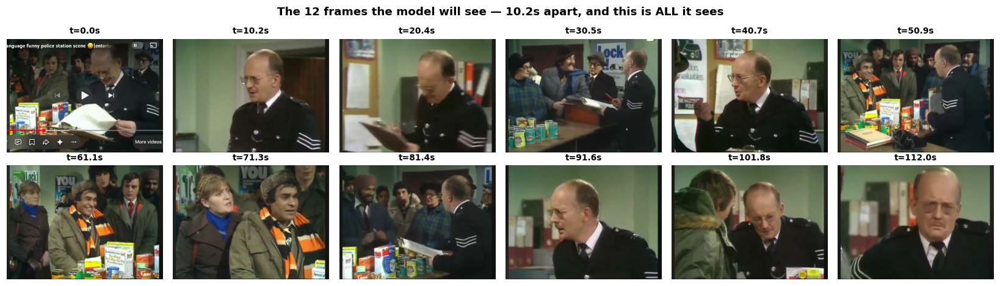

time: 496 ms (started: 2026-11-06 00:38:54 +05:30)


In [20]:
# Look at exactly what the model will receive. Nothing else -- no motion,
# no audio, no order, unless you say so.
fig, ax = plt.subplots(2, 6, figsize=(15, 4.4))
for a in ax.ravel():
    a.axis("off")
for a, f, t in zip(ax.ravel(), frames, stamps):
    a.imshow(f); a.set_title(f"t={t:.1f}s", fontsize=9)
fig.suptitle(f"The {len(frames)} frames the model will see — {stamps[1]-stamps[0]:.1f}s apart, "
             "and this is ALL it sees", fontweight="bold")
fig.tight_layout(); plt.show()

message has 26 parts: 1 preamble + 12 labels + 12 images + 1 question


[{'type': 'text',
  'text': 'These are frames sampled IN ORDER from one short video; each is labeled with its timestamp. Reason about what happens over time.'},
 {'type': 'text', 'text': '[frame @ 0.0s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 10.2s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 20.4s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 30.5s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 40.7s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 50.9s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 61.1s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'tex
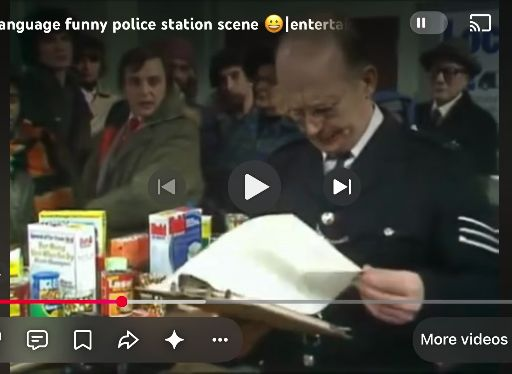
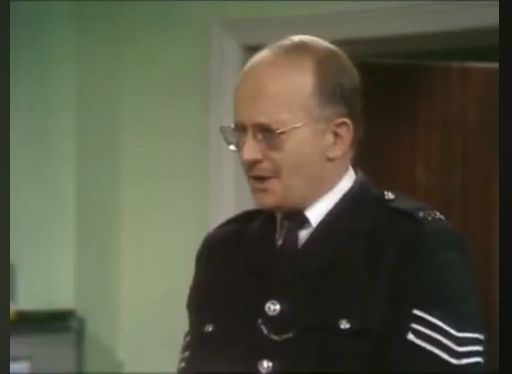
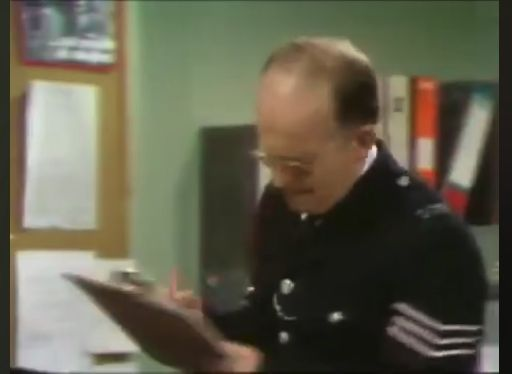
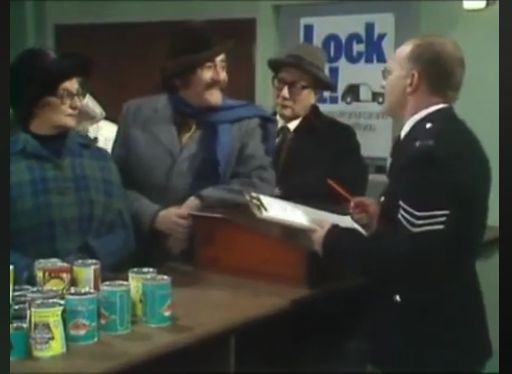
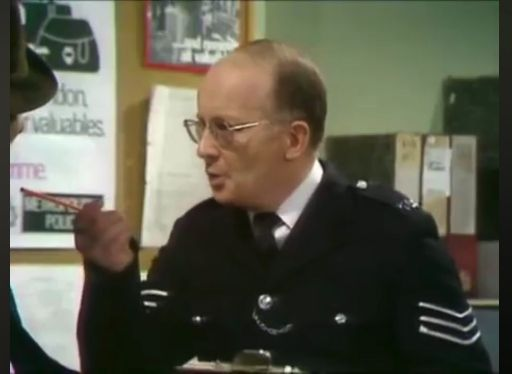
...
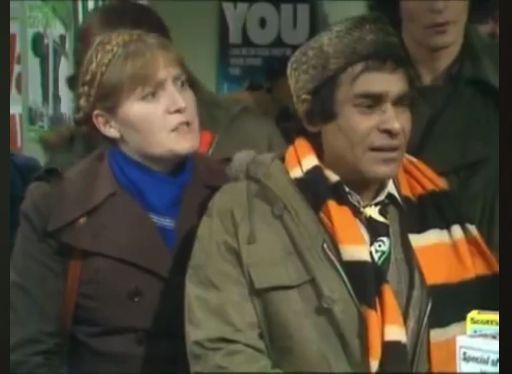
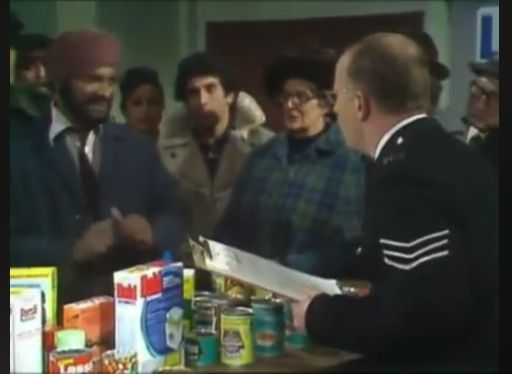
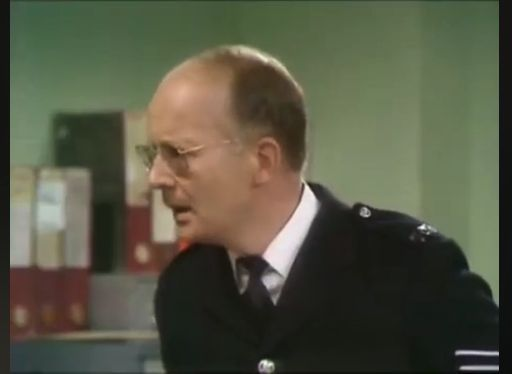
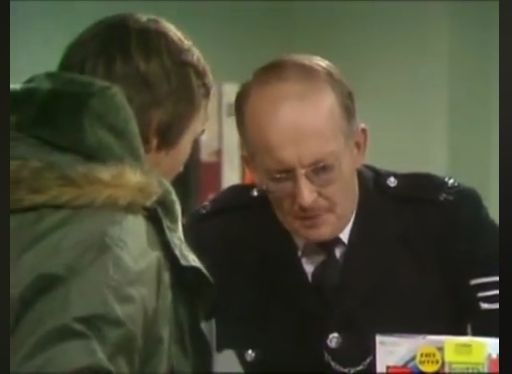
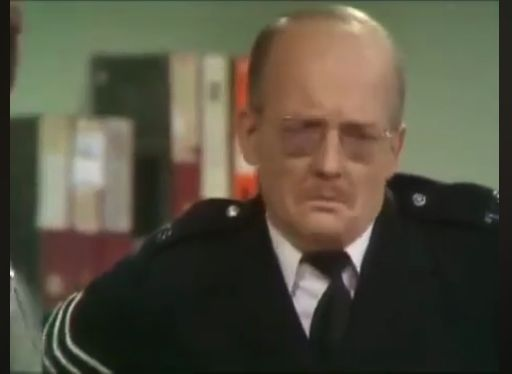

time: 11.1 ms (started: 2026-11-06 00:38:55 +05:30)


In [21]:
def frame_to_data_url(rgb, quality=80):
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)          # imencode wants BGR back
    ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return "data:image/jpeg;base64," + base64.b64encode(buf).decode("ascii")


content = [{"type": "text",
            "text": ("These are frames sampled IN ORDER from one short video; each is "
                     "labeled with its timestamp. Reason about what happens over time.")}]

for t, f in zip(stamps, frames):
    content.append({"type": "text", "text": f"[frame @ {t:.1f}s]"})      # order + time
    content.append({"type": "image_url",
                    "image_url": {"url": frame_to_data_url(f), "detail": "low"}})

content.append({"type": "text",
                "text": "In 2-3 sentences, describe what happens across the clip."})

print(f"message has {len(content)} parts: 1 preamble + "
      f"{len(frames)} labels + {len(frames)} images + 1 question")

content

In [22]:
# GOTCHA: gpt-5-* are REASONING models. Hidden reasoning tokens are billed against
# max_completion_tokens BEFORE any visible text -- too small a cap and the reasoning
# eats the whole budget and content comes back "". Give it headroom.
resp = client.chat.completions.create(
    model=VISION_MODEL,
    max_completion_tokens=2000,
    messages=[{"role": "user", "content": content}],
)

pretty_print(resp.choices[0].message.content)
print("\n[usage]", resp.usage)

A uniformed officer stands behind a counter covered with boxes and canned goods,
flipping through a clipboard as a crowd gathers. He talks to the group and
checks papers while people bring items forward, seemingly participating in some
kind exchange or donation. The mood lightens with smiles and interaction, but
the officer ends the sequence with a focused, slightly stern look as he wraps up
the exchange.

[usage] CompletionUsage(completion_tokens=981, prompt_tokens=3596, total_tokens=4577, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=896, rejected_prediction_tokens=0, text_tokens=None), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=None, cached_tokens=0, image_tokens=None, text_tokens=None))
time: 9.64 s (started: 2026-11-06 00:38:55 +05:30)


In [23]:
# --- pull the audio track out as a 16 kHz mono WAV --------------------------
import imageio_ffmpeg
FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()
AUDIO_PATH = "what_is_your_name_audio.wav"
# -vn drops the video; pcm WAV is universally readable (no codec risk).
subprocess.run([FFMPEG, "-y", "-i", VIDEO_PATH, "-vn", "-ac", "1", "-ar", "16000",
                AUDIO_PATH], capture_output=True, text=True)

y_clip, _ = sf.read(AUDIO_PATH, dtype="float32")
print(f"extracted -> {AUDIO_PATH}  "
      f"({os.path.getsize(AUDIO_PATH)/1e6:.2f} MB, {len(y_clip)/SR:.1f}s, 16 kHz mono)")
display(Audio(y_clip, rate=SR))

extracted -> what_is_your_name_audio.wav  (3.58 MB, 112.0s, 16 kHz mono)


time: 169 ms (started: 2026-11-06 00:39:04 +05:30)


In [24]:
# --- transcribe WITH segment timestamps ------------------------------------
# whisper-1 + verbose_json is the combination that returns segments; the newer
# gpt-4o-transcribe (Part 5) does not.
with open(AUDIO_PATH, "rb") as fh:
    tr = client.audio.transcriptions.create(
        model=SEGMENT_ASR,
        file=fh,
        response_format="verbose_json",
        timestamp_granularities=["segment"],
    )

segments = [{"start": s.start, "end": s.end, "text": s.text.strip()} for s in tr.segments]

print(f"{len(segments)} segments over {len(y_clip)/SR:.1f}s:\n")
for s in segments[:12]:
    print(f"  [{s['start']:5.1f}-{s['end']:5.1f}s] {s['text']}")
print("  ...")

56 segments over 112.0s:

  [  0.0-  2.6s] I've just given you five pounds to, uh, forgive it.
  [  2.6-  3.8s] Oh, no, sir.
  [  3.8-  8.0s] You very kindly donated five pounds to our charity fund.
  [  8.0- 11.0s] It wasn't meant as a bribe, was it, sir?
  [ 11.0- 12.1s] No.
  [ 12.1- 13.9s] Good.
  [ 13.9- 16.2s] Now, let's take a few names.
  [ 16.2- 17.7s] You, madam. Sorry.
  [ 17.7- 19.3s] Miss.
  [ 19.3- 22.2s] Cockney.
  [ 22.2- 23.8s] Thank you.
  [ 23.8- 24.5s] You, sir.
  ...
time: 8.7 s (started: 2026-11-06 00:39:55 +05:30)


In [25]:
for s in segments:
    print(f"  [{s['start']:5.1f}-{s['end']:5.1f}s] {s['text']}")

  [  0.0-  2.6s] I've just given you five pounds to, uh, forgive it.
  [  2.6-  3.8s] Oh, no, sir.
  [  3.8-  8.0s] You very kindly donated five pounds to our charity fund.
  [  8.0- 11.0s] It wasn't meant as a bribe, was it, sir?
  [ 11.0- 12.1s] No.
  [ 12.1- 13.9s] Good.
  [ 13.9- 16.2s] Now, let's take a few names.
  [ 16.2- 17.7s] You, madam. Sorry.
  [ 17.7- 19.3s] Miss.
  [ 19.3- 22.2s] Cockney.
  [ 22.2- 23.8s] Thank you.
  [ 23.8- 24.5s] You, sir.
  [ 24.5- 25.0s] Me.
  [ 25.0- 26.0s] What's your name?
  [ 26.0- 28.3s] Por favor.
  [ 28.3- 31.2s] How do you spell that?
  [ 31.2- 32.4s] That's not his name.
  [ 32.4- 34.9s] Oh, giving me a false name, eh?
  [ 34.9- 36.2s] Por favor.
  [ 36.2- 41.2s] I'll come back to you, Mr. Por favor, or whatever your name is.
  [ 41.2- 42.4s] You.
  [ 42.4- 43.9s] Yes, please.
  [ 43.9- 46.0s] What is your name?
  [ 46.0- 46.8s] Oh, no.
  [ 46.8- 49.2s] What is not my name?
  [ 49.2- 52.1s] I don't want to know what your name is not.
  [ 52.

In [26]:
# --- FUSION: transcript + a few keyframes -> a grounded, time-cited answer ---
# This is the pattern you ship. The transcript is the 'what was said'; the
# keyframes are the 'what was shown'. Together, cheaply, they beat dense frames.
transcript_block = "\n".join(
    f"[{s['start']:.1f}-{s['end']:.1f}s] {s['text']}" for s in segments)

transcript_block

"[0.0-2.6s] I've just given you five pounds to, uh, forgive it.\n[2.6-3.8s] Oh, no, sir.\n[3.8-8.0s] You very kindly donated five pounds to our charity fund.\n[8.0-11.0s] It wasn't meant as a bribe, was it, sir?\n[11.0-12.1s] No.\n[12.1-13.9s] Good.\n[13.9-16.2s] Now, let's take a few names.\n[16.2-17.7s] You, madam. Sorry.\n[17.7-19.3s] Miss.\n[19.3-22.2s] Cockney.\n[22.2-23.8s] Thank you.\n[23.8-24.5s] You, sir.\n[24.5-25.0s] Me.\n[25.0-26.0s] What's your name?\n[26.0-28.3s] Por favor.\n[28.3-31.2s] How do you spell that?\n[31.2-32.4s] That's not his name.\n[32.4-34.9s] Oh, giving me a false name, eh?\n[34.9-36.2s] Por favor.\n[36.2-41.2s] I'll come back to you, Mr. Por favor, or whatever your name is.\n[41.2-42.4s] You.\n[42.4-43.9s] Yes, please.\n[43.9-46.0s] What is your name?\n[46.0-46.8s] Oh, no.\n[46.8-49.2s] What is not my name?\n[49.2-52.1s] I don't want to know what your name is not.\n[52.1-54.1s] What is your name?\n[54.1-56.4s] And I'm telling you it is not.\n[56.4-57.3s] 

time: 4.8 ms (started: 2026-11-06 00:40:31 +05:30)


In [27]:
fused = [{"type": "text",
          "text": "TRANSCRIPT (timestamped):\n" + transcript_block +
                  "\n\nBelow are a few keyframes for visual context."}]

for t, f in zip(stamps, frames):
    fused.append({"type": "text", "text": f"[frame @ {t:.1f}s]"})
    fused.append({"type": "image_url",
                  "image_url": {"url": frame_to_data_url(f), "detail": "low"}})

fused.append({"type": "text",
              "text": "Summarize what happens in this clip, citing timestamps."})

# 2000 was enough in Part 8 and is NOT enough here: 43 transcript segments is a lot
# more to reason over, and the hidden reasoning tokens are spent BEFORE any visible
# text. At 2000 this call returns "" and raises nothing. Budget generously.
resp_fused = client.chat.completions.create(
    model=VISION_MODEL,
    max_completion_tokens=6000,
    messages=[{"role": "user", "content": fused}],
)

pretty_print(resp_fused.choices[0].message.content)
print("\nframes-only prompt tokens :", resp.usage.prompt_tokens)
print("fused        prompt tokens :", resp_fused.usage.prompt_tokens)
print("reasoning tokens spent     :",
      resp_fused.usage.completion_tokens_details.reasoning_tokens)

Here’s a concise run-through of what happens, with key timestamps:  - 0.0–2.6s:
A man says he’s given five pounds “to forgive it.” The officer says it’s not a
bribe. - 2.6–8.0s: The officer confirms the donation went to charity, not as a
bribe; the man insists it wasn’t a bribe. - 8.0–16.2s: The officer moves to take
a few names from the crowd: “You, madam… Miss… Cockney.” The crowd reacts and
thanks are exchanged. - 16.2–41.2s: Names begin being volunteered in a farcical
way. One person says “Por favor” as a name, others question spelling, and
there’s back-and-forth about whether that’s a real name. The officer pretends to
note people as “Mr. Por favor” and promises to come back to that person. -
41.2–72.9s: The name-gathering devolves into wordplay about names. Repeated
lines like “What is your name?” “That is not his name,” and “Por favor” fuel the
confusion. A running gag plays on the idea of naming someone “Nine” and whether
that is indeed the name. - 72.9–94.7s: The exchanges con

[{'type': 'text',
  'text': "TRANSCRIPT (timestamped):\n[0.0-2.6s] I've just given you five pounds to, uh, forgive it.\n[2.6-3.8s] Oh, no, sir.\n[3.8-8.0s] You very kindly donated five pounds to our charity fund.\n[8.0-11.0s] It wasn't meant as a bribe, was it, sir?\n[11.0-12.1s] No.\n[12.1-13.9s] Good.\n[13.9-16.2s] Now, let's take a few names.\n[16.2-17.7s] You, madam. Sorry.\n[17.7-19.3s] Miss.\n[19.3-22.2s] Cockney.\n[22.2-23.8s] Thank you.\n[23.8-24.5s] You, sir.\n[24.5-25.0s] Me.\n[25.0-26.0s] What's your name?\n[26.0-28.3s] Por favor.\n[28.3-31.2s] How do you spell that?\n[31.2-32.4s] That's not his name.\n[32.4-34.9s] Oh, giving me a false name, eh?\n[34.9-36.2s] Por favor.\n[36.2-41.2s] I'll come back to you, Mr. Por favor, or whatever your name is.\n[41.2-42.4s] You.\n[42.4-43.9s] Yes, please.\n[43.9-46.0s] What is your name?\n[46.0-46.8s] Oh, no.\n[46.8-49.2s] What is not my name?\n[49.2-52.1s] I don't want to know what your name is not.\n[52.1-54.1s] What is your name?\n[54
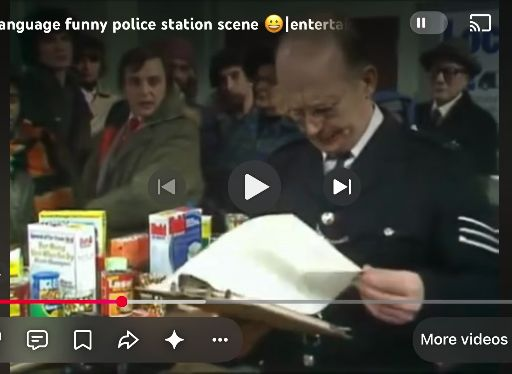
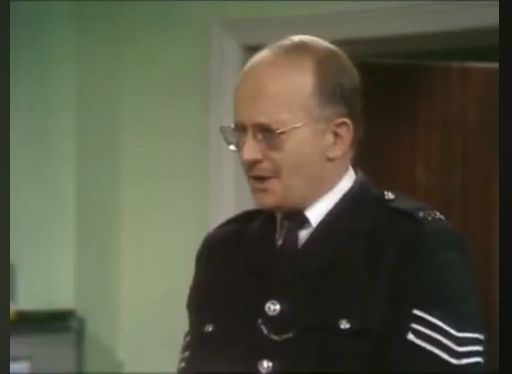
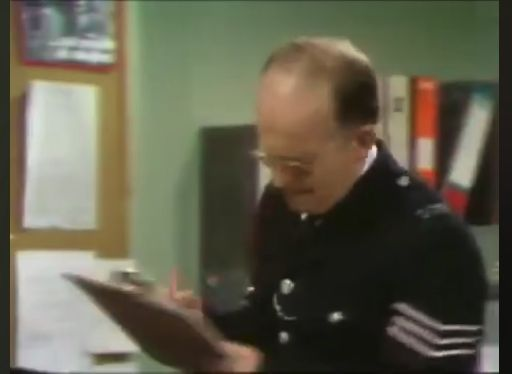
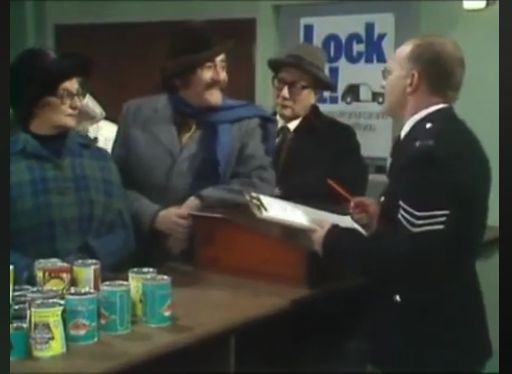
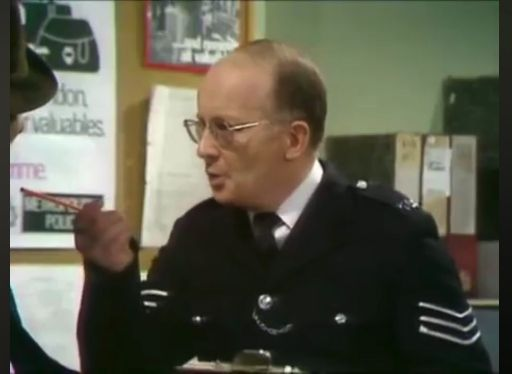
...
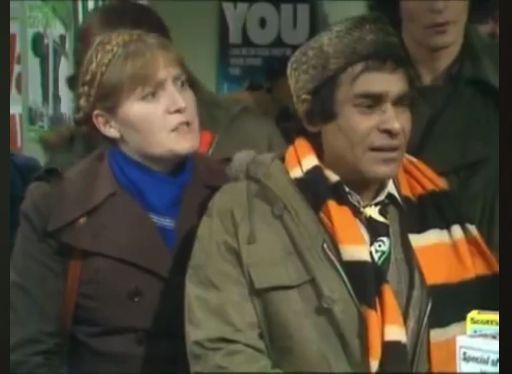
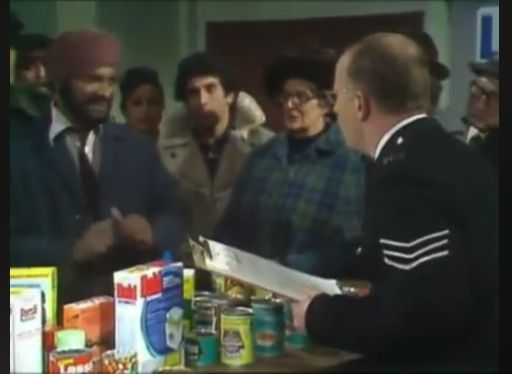
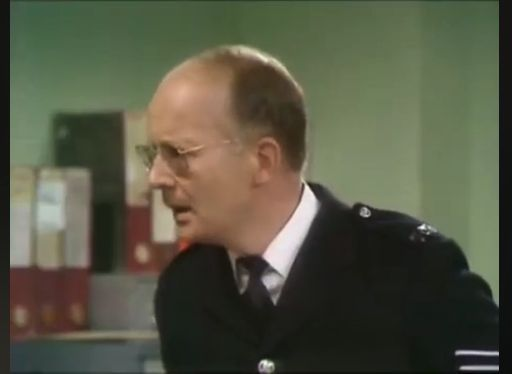
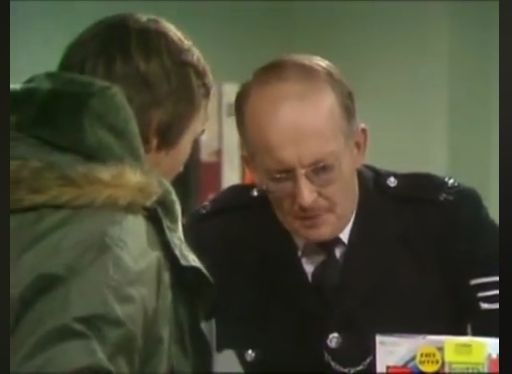
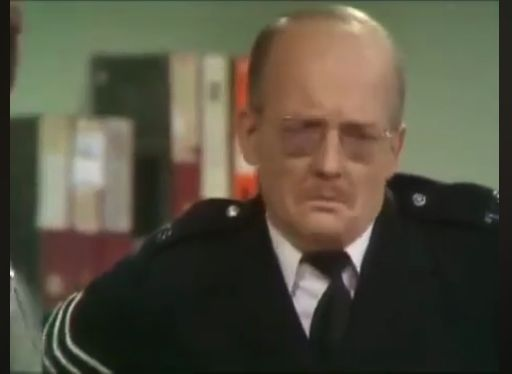

time: 5.72 ms (started: 2026-11-06 00:43:18 +05:30)


In [28]:
fused

# Video Part 2 - Mr. Bean

In [29]:
VIDEO_PATH = "/Users/pranjalimhatre/Scaler/AdvancedAI/LLMs_OtherModalities/AI Modalities: Video/videos/MRBean.mov"

time: 209 μs (started: 2026-11-06 00:44:13 +05:30)


In [30]:
# Read metadata WITHOUT decoding a single frame (cheap).
cap      = cv2.VideoCapture(VIDEO_PATH)
fps      = cap.get(cv2.CAP_PROP_FPS) or 25.0
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
H        = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
W        = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
cap.release()

print(f"shape (T,H,W,C) : ({n_frames}, {H}, {W}, 3)")
print(f"fps / duration  : {fps:.2f} fps  /  {n_frames/fps:.1f} s")
print(f"raw decoded RGB : {n_frames * H * W * 3 / 1e6:,.0f} MB in memory")

# The translation that actually drives every decision: frames -> tokens -> dollars.
TOK_PER_HIGH_FRAME = 765          # ~a 1024px frame at detail="high"
PRICE_PER_1M_INPUT = 2.50         # illustrative $ / 1M input tokens -- CHECK CURRENT PRICING
tok_all = n_frames * TOK_PER_HIGH_FRAME

print(f"\nif you naively sent EVERY frame at high detail:")
print(f"  {n_frames} frames x {TOK_PER_HIGH_FRAME} tok = {tok_all:,} image-tokens")
print(f"  ~= {tok_all/128_000:.1f}x a 128k context window, "
      f"~${tok_all/1e6*PRICE_PER_1M_INPUT:,.2f} per call")
print("  -> impossible. The whole game is sampling FEW frames well.")

shape (T,H,W,C) : (5083, 1180, 2100, 3)
fps / duration  : 27.83 fps  /  182.7 s
raw decoded RGB : 37,787 MB in memory

if you naively sent EVERY frame at high detail:
  5083 frames x 765 tok = 3,888,495 image-tokens
  ~= 30.4x a 128k context window, ~$9.72 per call
  -> impossible. The whole game is sampling FEW frames well.
time: 12.8 ms (started: 2026-11-06 00:44:23 +05:30)


In [31]:
NUM_FRAMES, MAX_SIDE = 36, 512

# Which frame indices do we want? Uniformly spaced across the whole clip.
wanted = set(np.linspace(0, n_frames - 1, NUM_FRAMES).round().astype(int).tolist())

cap = cv2.VideoCapture(VIDEO_PATH)
frames, stamps, i = [], [], 0
while True:
    ok, bgr = cap.read()               # decode SEQUENTIALLY -- seeking lies on some codecs
    if not ok:
        break
    if i in wanted:
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)      # GOTCHA: OpenCV decodes BGR!
        h, w = rgb.shape[:2]
        scale = min(1.0, MAX_SIDE / max(h, w))          # shrink only, never upscale
        if scale < 1.0:
            rgb = cv2.resize(rgb, (int(w * scale), int(h * scale)))
        frames.append(rgb)
        stamps.append(i / fps)                          # REMEMBER WHEN -- Part 8 needs it
    i += 1
cap.release()

print(f"decoded {i} frames, kept {len(frames)}")
print(f"timestamps (s): {[round(t, 1) for t in stamps]}")
print(f"frame shape after resize: {frames[0].shape}")

decoded 5083 frames, kept 36
timestamps (s): [0.0, 5.2, 10.4, 15.7, 20.9, 26.1, 31.3, 36.5, 41.8, 47.0, 52.2, 57.4, 62.6, 67.8, 73.1, 78.3, 83.5, 88.7, 93.9, 99.2, 104.4, 109.6, 114.8, 120.0, 125.2, 130.5, 135.7, 140.9, 146.1, 151.3, 156.5, 161.8, 167.0, 172.2, 177.4, 182.6]
frame shape after resize: (287, 512, 3)
time: 16 s (started: 2026-11-06 00:44:37 +05:30)


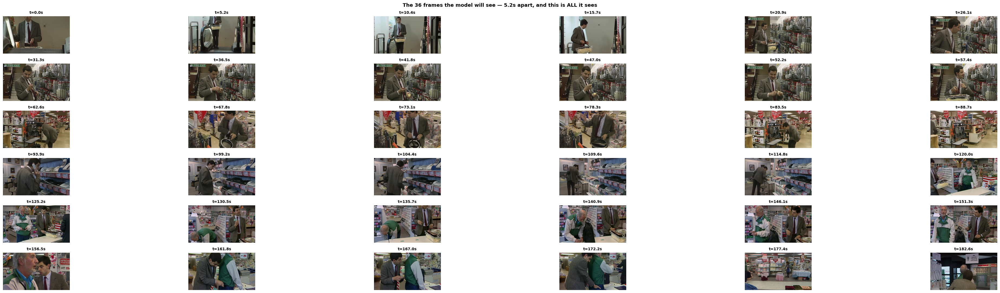

time: 753 ms (started: 2026-11-06 00:45:08 +05:30)


In [32]:
# Look at exactly what the model will receive. Nothing else -- no motion,
# no audio, no order, unless you say so.
fig, ax = plt.subplots(6, 6, figsize=(40, 10))
for a in ax.ravel():
    a.axis("off")
for a, f, t in zip(ax.ravel(), frames, stamps):
    a.imshow(f); a.set_title(f"t={t:.1f}s", fontsize=9)
fig.suptitle(f"The {len(frames)} frames the model will see — {stamps[1]-stamps[0]:.1f}s apart, "
             "and this is ALL it sees", fontweight="bold")
fig.tight_layout(); plt.show()

message has 74 parts: 1 preamble + 36 labels + 36 images + 1 question


[{'type': 'text',
  'text': 'These are frames sampled IN ORDER from one short video; each is labeled with its timestamp. Reason about what happens over time.'},
 {'type': 'text', 'text': '[frame @ 0.0s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 5.2s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 10.4s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 15.7s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 20.9s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 26.1s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 31.3s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text
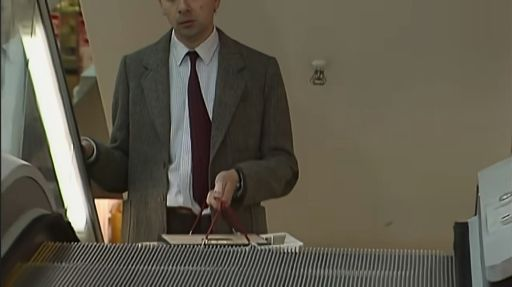
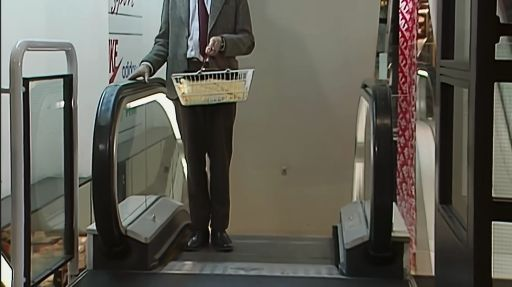
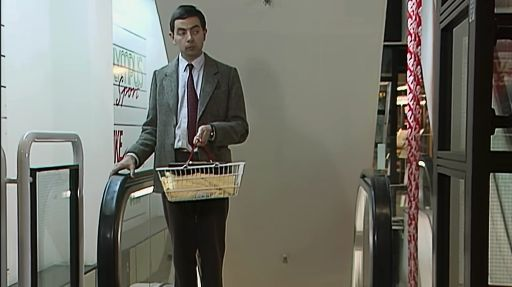
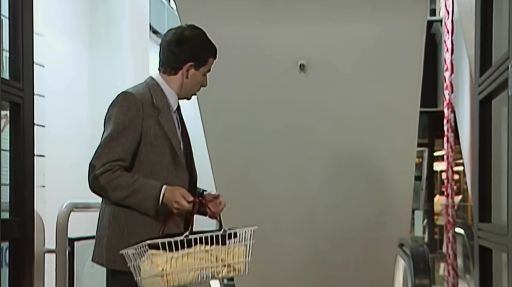
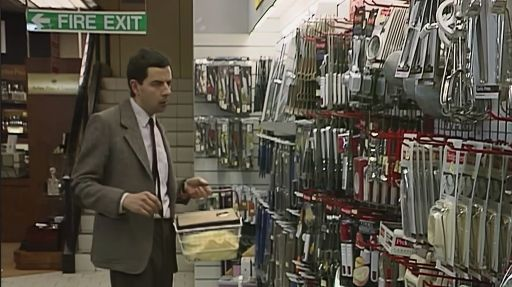
...
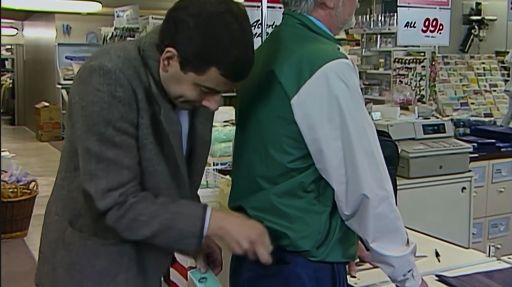
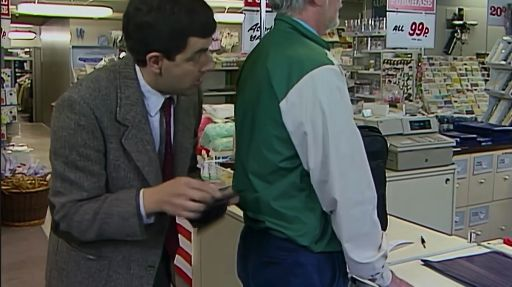
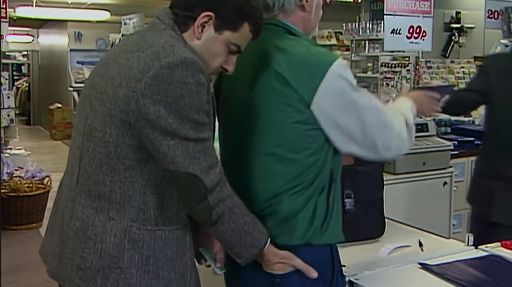
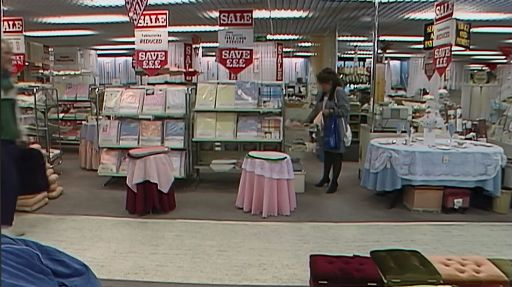
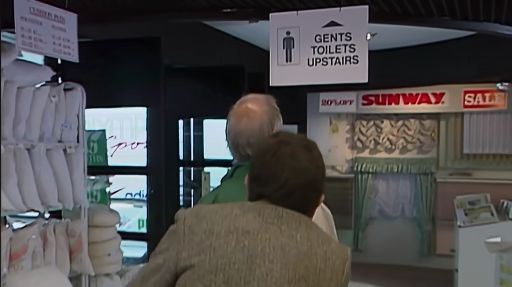

time: 33.3 ms (started: 2026-11-06 00:45:19 +05:30)


In [33]:
def frame_to_data_url(rgb, quality=80):
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)          # imencode wants BGR back
    ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return "data:image/jpeg;base64," + base64.b64encode(buf).decode("ascii")


content = [{"type": "text",
            "text": ("These are frames sampled IN ORDER from one short video; each is "
                     "labeled with its timestamp. Reason about what happens over time.")}]

for t, f in zip(stamps, frames):
    content.append({"type": "text", "text": f"[frame @ {t:.1f}s]"})      # order + time
    content.append({"type": "image_url",
                    "image_url": {"url": frame_to_data_url(f), "detail": "low"}})

content.append({"type": "text",
                "text": "In 2-3 sentences, describe what happens across the clip."})

print(f"message has {len(content)} parts: 1 preamble + "
      f"{len(frames)} labels + {len(frames)} images + 1 question")

content

In [34]:
# GOTCHA: gpt-5-* are REASONING models. Hidden reasoning tokens are billed against
# max_completion_tokens BEFORE any visible text -- too small a cap and the reasoning
# eats the whole budget and content comes back "". Give it headroom.
resp = client.chat.completions.create(
    model=VISION_MODEL,
    max_completion_tokens=2000,
    messages=[{"role": "user", "content": content}],
)

pretty_print(resp.choices[0].message.content)
print("\n[usage]", resp.usage)

A man in a suit goes on a shopping trip in a department store, picking up
various cookware (pots/pans) and placing them in a basket as he moves through
the aisles. He then proceeds to the checkout, interacts with staff and another
shopper, and after paying, leaves the store with his purchases. The sequence
shows him wandering between displays and finally exiting with his basket.

[usage] CompletionUsage(completion_tokens=1238, prompt_tokens=8108, total_tokens=9346, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=1152, rejected_prediction_tokens=0, text_tokens=None), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=None, cached_tokens=0, image_tokens=None, text_tokens=None))
time: 15.1 s (started: 2026-11-06 00:45:48 +05:30)


In [35]:
# --- pull the audio track out as a 16 kHz mono WAV --------------------------
import imageio_ffmpeg
FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()
AUDIO_PATH = "mrbean.wav"

# -vn drops the video; pcm WAV is universally readable (no codec risk).
subprocess.run([FFMPEG, "-y", "-i", VIDEO_PATH, "-vn", "-ac", "1", "-ar", "16000",
                AUDIO_PATH], capture_output=True, text=True)

y_clip, _ = sf.read(AUDIO_PATH, dtype="float32")
print(f"extracted -> {AUDIO_PATH}  "
      f"({os.path.getsize(AUDIO_PATH)/1e6:.2f} MB, {len(y_clip)/SR:.1f}s, 16 kHz mono)")
display(Audio(y_clip, rate=SR))

extracted -> mrbean.wav  (5.84 MB, 182.6s, 16 kHz mono)


time: 189 ms (started: 2026-11-06 00:46:13 +05:30)


In [36]:
# --- transcribe WITH segment timestamps ------------------------------------
# whisper-1 + verbose_json is the combination that returns segments; the newer
# gpt-4o-transcribe (Part 5) does not.
with open(AUDIO_PATH, "rb") as fh:
    tr = client.audio.transcriptions.create(
        model=SEGMENT_ASR,
        file=fh,
        response_format="verbose_json",
        timestamp_granularities=["segment"],
    )

segments = [{"start": s.start, "end": s.end, "text": s.text.strip()} for s in tr.segments]

print(f"{len(segments)} segments over {len(y_clip)/SR:.1f}s:\n")
for s in segments:
    print(f"  [{s['start']:5.1f}-{s['end']:5.1f}s] {s['text']}")
print("  ...")

5 segments over 182.6s:

  [  0.0-  2.0s] I
  [ 30.0- 32.0s] I
  [ 60.8- 64.6s] Just a second.
  [ 64.6- 73.2s] Unless you're petrifying.
  [ 73.2- 84.2s] Maybe I could...
  ...
time: 14 s (started: 2026-11-06 00:46:46 +05:30)


In [37]:
# --- FUSION: transcript + a few keyframes -> a grounded, time-cited answer ---
# This is the pattern you ship. The transcript is the 'what was said'; the
# keyframes are the 'what was shown'. Together, cheaply, they beat dense frames.
transcript_block = "\n".join(
    f"[{s['start']:.1f}-{s['end']:.1f}s] {s['text']}" for s in segments)



fused = [{"type": "text",
          "text": "TRANSCRIPT (timestamped):\n" + transcript_block +
                  "\n\nBelow are a few keyframes for visual context."}]

for t, f in zip(stamps, frames):
    fused.append({"type": "text", "text": f"[frame @ {t:.1f}s]"})
    fused.append({"type": "image_url",
                  "image_url": {"url": frame_to_data_url(f), "detail": "low"}})

fused.append({"type": "text",
              "text": "Summarize what happens in this clip, citing timestamps."})

# 2000 was enough in Part 8 and is NOT enough here: 43 transcript segments is a lot
# more to reason over, and the hidden reasoning tokens are spent BEFORE any visible
# text. At 2000 this call returns "" and raises nothing. Budget generously.
resp_fused = client.chat.completions.create(
    model=VISION_MODEL,
    max_completion_tokens=6000,
    messages=[{"role": "user", "content": fused}],
)

pretty_print(resp_fused.choices[0].message.content)
print("\nframes-only prompt tokens :", resp.usage.prompt_tokens)
print("fused        prompt tokens :", resp_fused.usage.prompt_tokens)
print("reasoning tokens spent     :",
      resp_fused.usage.completion_tokens_details.reasoning_tokens)

Here's a concise, timestamped summary of what happens in the clip:  - 0:00–2:00:
The main character, a man in a gray suit and red tie, is introduced in a
department-store setting (he’s shown speaking a bit with “I” in the dialogue).
He enters with a shopping basket and starts moving through the store.  -
5:20–31:30: He browses a cookware/housewares area. He picks up several items
(pans, utensils) and places them in his basket, moving along the display walls
as he shops.  - 60:08–64:06 and 64:06–73:20: He pauses and speaks a few lines
(“Just a second.” / “Unless you’re petrifying.” / “Maybe I could…”), suggesting
hesitation or consideration as he continues to look at items.  - 60:08–84:20
(roughly): He remains in the housewares area, continuing to handle and inspect
cookware, including a frying pan, with a mix of hanging and shelf displays
visible.  - 93:39–120:00: The scene cuts to him at a different department
(appears to be an electronics/office counter). He uses a phone and continue

[{'type': 'text',
  'text': "TRANSCRIPT (timestamped):\n[0.0-2.0s] I\n[30.0-32.0s] I\n[60.8-64.6s] Just a second.\n[64.6-73.2s] Unless you're petrifying.\n[73.2-84.2s] Maybe I could...\n\nBelow are a few keyframes for visual context."},
 {'type': 'text', 'text': '[frame @ 0.0s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 5.2s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 10.4s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 15.7s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 20.9s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 26.1s]'},
 {'type': 'image_url',
  'image_url': {'url': '',
   'detail': 'low'}},
 {'type': 'text', 'text': '[frame @ 31.3s]'},
 {'type': '
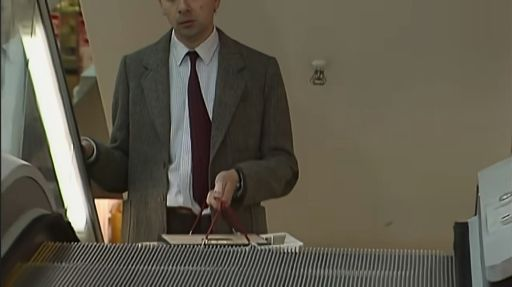
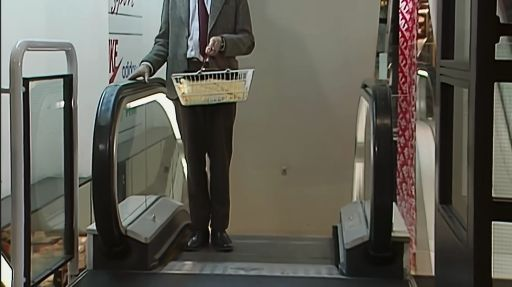
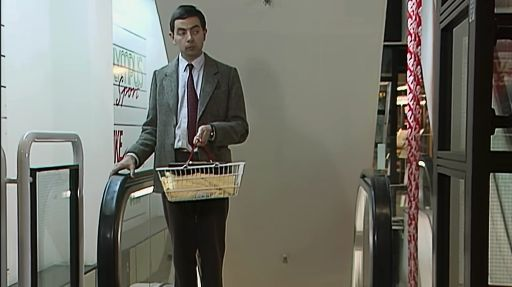
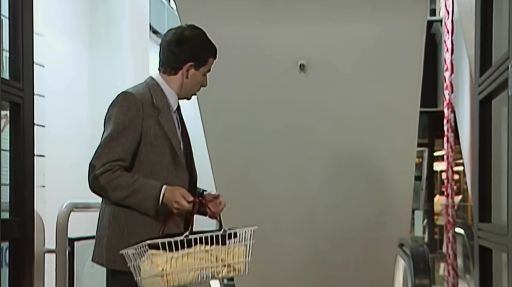
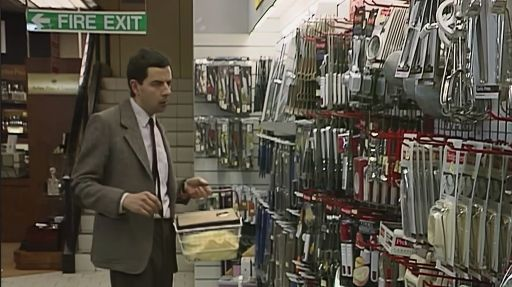
...
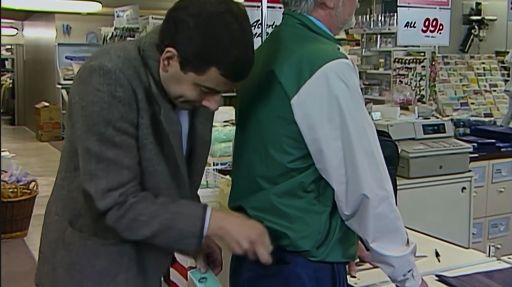
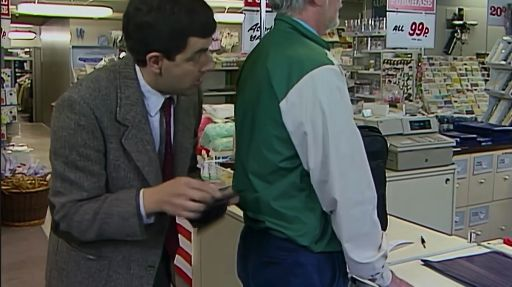
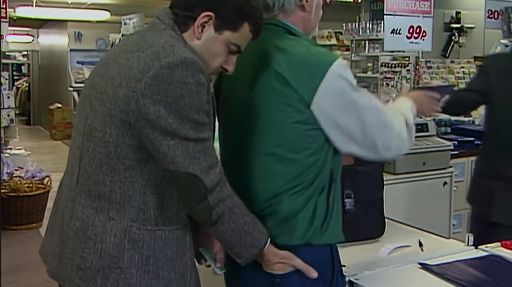
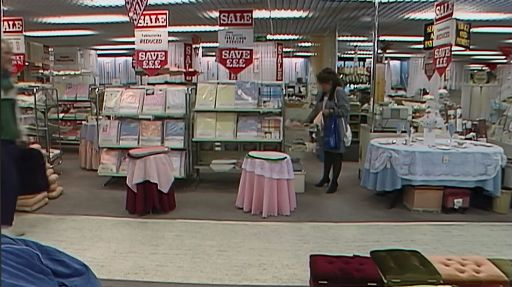
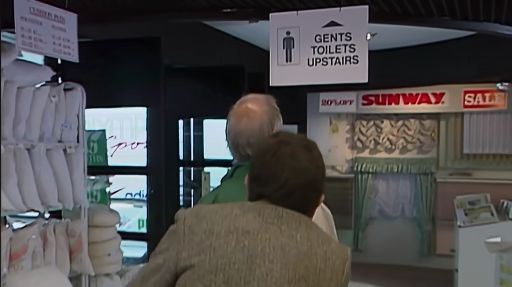

time: 9.05 ms (started: 2026-11-06 00:49:37 +05:30)


In [38]:
fused